# Evaluación final de los modelos
### Predicción de intención de compra en tiendas online

**Objetivo:** comprobar cómo funcionan los modelos con datos que no han utilizado durante el entrenamiento ni durante la selección de hiperparámetros. Por eso usamos el conjunto de prueba que habíamos reservado al principio.

Vamos a comparar los dos modelos seleccionados:

- **CatBoost:** usa 22 características, incluyendo las nuevas variables creadas mediante ingeniería de características y los hiperparámetros que hemos elegido.

- **Random Forest:** usa las 17 características originales y su configuración optimizada.

Para evaluar su rendimiento vamos a usar Average Precision, ROC AUC, Precision, Recall y F1. También analizaremos sus matrices de confusión para ver qué tipo de errores comete cada modelo. Antes de evaluar los mdoelos con el conjunto de prueba, vamos a estudiar qué umbral de clasificación es el más adecuado utilizando solo los datos de entrenamiento.

Por último usaremos el conjunto de prueba para realizar la evaluación final. Utilizaremos el conjunto de prueba para comparar los dos modelos candidatos y seleccionar el definitivo. No reajustaremos sus hiperparámetros ni sus umbrales a partir de estos resultados.

## 1. Preparación de los datos y modelos

Reproducimos la misma limpieza y partición estratificada
80/20 empleadas en los notebooks anteriores, con semilla 42.

Mantenemos los 125 registros duplicados fuera del conjunto
utilizado para el entrenamiento y la evaluación.

Random Forest utilizará las 17 características originales,
mientras que CatBoost incorporará las cinco variables
derivadas seleccionadas experimentalmente.

No aplicaremos técnicas de balanceo, ya que no proporcionaron
mejoras relevantes de Average Precision.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

from catboost import CatBoostClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# Datos

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

datos = pd.read_csv(
    RAIZ / "data" / "raw"/ "online_shoppers_intention.csv"
)

datos = datos.drop_duplicates().reset_index(drop=True)

X = datos.drop(columns="Revenue")
y = datos["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

variables_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(f"Entrenamiento: {len(X_train):,} sesiones")
print(f"Prueba: {len(X_test):,} sesiones")
print(f"Proporción de compradores (train): {y_train.mean():.2%}")

Entrenamiento: 9,764 sesiones
Prueba: 2,441 sesiones
Proporción de compradores (train): 15.63%


In [3]:
# Características derivadas para CatBoost

def crear_caracteristicas(X):
    X = X.copy()

    X["Has_PageValue"] = (X["PageValues"] > 0).astype(int)

    X["Total_Pages"] = (
        X["Administrative"]
        + X["Informational"]
        + X["ProductRelated"]
    )

    X["Total_Duration"] = (
        X["Administrative_Duration"]
        + X["Informational_Duration"]
        + X["ProductRelated_Duration"]
    )

    X["Avg_Product_Time"] = (
        X["ProductRelated_Duration"]
        / X["ProductRelated"].clip(lower=1)
    )

    X["Product_Page_Share"] = (
        X["ProductRelated"]
        / X["Total_Pages"].clip(lower=1)
    )

    return X


X_train_cb = crear_caracteristicas(X_train)

for columna in variables_categoricas:
    X_train_cb[columna] = X_train_cb[columna].astype(str)

print(f"Características Random Forest: {X_train.shape[1]}")
print(f"Características CatBoost: {X_train_cb.shape[1]}")

Características Random Forest: 17
Características CatBoost: 22


## 2. Selección del umbral de clasificación

Los modelos producen probabilidades estimadas de compra.
Para convertirlas en predicciones binarias necesitamos
establecer un umbral de decisión.

El umbral habitual de 0,5 no tiene por qué proporcionar el
mejor equilibrio entre Precision y Recall, especialmente
ante un conjunto de datos desequilibrado.

Seleccionaremos el umbral utilizando exclusivamente el
conjunto de entrenamiento y reservaremos el test para
la evaluación final.

### 2.1. Predicciones fuera de fold (OOF)

Generamos probabilidades mediante validación cruzada
estratificada de cinco folds.

En cada partición, el modelo se entrena con cuatro folds y
predice las sesiones del quinto, que no ha utilizado para
ajustar sus parámetros.

Al finalizar, disponemos de una probabilidad para cada
sesión de entrenamiento, obtenida sin entrenar el modelo
sobre esa misma sesión.

Estas predicciones permitirán estudiar los umbrales de
clasificación de Random Forest y CatBoost.

Los hiperparámetros permanecen fijos según las decisiones
tomadas en los notebooks anteriores.

In [4]:
probabilidades_oof = pd.DataFrame(
    index=X_train.index,
    columns=["Random Forest", "CatBoost"],
    dtype=float
)

numericas_rf = [
    c for c in X_train.columns
    if c not in variables_categoricas
]

for fold, (idx_ent, idx_val) in enumerate(
    cv.split(X_train, y_train), start=1
):

    print(f"Evaluando fold {fold}/5...")

    # Random Forest

    preprocesador_rf = ColumnTransformer([
        ("num", "passthrough", numericas_rf),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), variables_categoricas)
    ])

    modelo_rf = Pipeline([
        ("preprocesamiento", preprocesador_rf),
        ("clasificador", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=8,
            max_features=0.5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    modelo_rf.fit(
        X_train.iloc[idx_ent],
        y_train.iloc[idx_ent]
    )

    probabilidades_oof.iloc[
        idx_val, 0
    ] = modelo_rf.predict_proba(
        X_train.iloc[idx_val]
    )[:, 1]

    # CatBoost

    modelo_cb = CatBoostClassifier(
        iterations=300,
        depth=8,
        learning_rate=0.02,
        l2_leaf_reg=1,
        loss_function="Logloss",
        random_seed=RANDOM_STATE,
        thread_count=4,
        verbose=False,
        allow_writing_files=False
    )

    modelo_cb.fit(
        X_train_cb.iloc[idx_ent],
        y_train.iloc[idx_ent],
        cat_features=variables_categoricas
    )

    probabilidades_oof.iloc[
        idx_val, 1
    ] = modelo_cb.predict_proba(
        X_train_cb.iloc[idx_val]
    )[:, 1]


# Comprobar que todas las sesiones tienen predicción
assert probabilidades_oof.notna().all().all()

print("\nPredicciones OOF calculadas correctamente.")
print(f"Sesiones evaluadas: {len(probabilidades_oof):,}")

Evaluando fold 1/5...
Evaluando fold 2/5...
Evaluando fold 3/5...
Evaluando fold 4/5...
Evaluando fold 5/5...

Predicciones OOF calculadas correctamente.
Sesiones evaluadas: 9,764


In [5]:
# Rendimiento de las predicciones OOF

resultados_oof = []

for nombre in probabilidades_oof.columns:

    probabilidades = probabilidades_oof[nombre]

    predicciones = (
        probabilidades >= 0.5
    ).astype(int)

    resultados_oof.append({
        "Modelo": nombre,
        "AP": average_precision_score(
            y_train, probabilidades
        ),
        "ROC AUC": roc_auc_score(
            y_train, probabilidades
        ),
        "F1 (umbral 0.5)": f1_score(
            y_train, predicciones
        )
    })

tabla_oof = pd.DataFrame(
    resultados_oof
).set_index("Modelo")

display(
    tabla_oof.style
    .format("{:.4f}")
    .background_gradient(
        subset=["AP"],
        cmap="Blues"
    )
)

,AP,ROC AUC,F1 (umbral 0.5)
Modelo,,,
Random Forest,0.7536,0.9322,0.6609
CatBoost,0.7569,0.9342,0.6603


### 2.2. Optimización del umbral de clasificación

El umbral de decisión determina a partir de qué probabilidad
una sesión se clasifica como compradora.

Reducirlo suele aumentar el Recall, al identificar más
compradores, pero también puede reducir la Precision al
incrementar los falsos positivos.

Estudiaremos la evolución de Precision, Recall y F1 para
diferentes umbrales y seleccionaremos aquel que maximice
F1 en las predicciones out-of-fold.

Mantendremos también el umbral de 0,5 como referencia.

In [6]:
umbrales = np.linspace(0.01, 0.99, 197)
resultados_umbrales = []
curvas_umbrales = {}

for nombre in probabilidades_oof.columns:

    probs = probabilidades_oof[nombre].to_numpy()
    y_real = y_train.to_numpy()

    precision_valores = []
    recall_valores = []
    f1_valores = []

    for umbral in umbrales:

        pred = (probs >= umbral).astype(int)

        precision_valores.append(
            precision_score(y_real, pred, zero_division=0)
        )
        recall_valores.append(
            recall_score(y_real, pred, zero_division=0)
        )
        f1_valores.append(
            f1_score(y_real, pred, zero_division=0)
        )

    precision_valores = np.array(precision_valores)
    recall_valores = np.array(recall_valores)
    f1_valores = np.array(f1_valores)

    indice_mejor = np.argmax(f1_valores)
    umbral_optimo = umbrales[indice_mejor]

    resultados_umbrales.append({
        "Modelo": nombre,
        "Umbral óptimo": umbral_optimo,
        "Precision": precision_valores[indice_mejor],
        "Recall": recall_valores[indice_mejor],
        "F1 óptimo": f1_valores[indice_mejor],
        "F1 con 0,5": tabla_oof.loc[nombre, "F1 (umbral 0.5)"]
    })

    curvas_umbrales[nombre] = {
        "Precision": precision_valores,
        "Recall": recall_valores,
        "F1": f1_valores,
        "Umbral óptimo": umbral_optimo
    }

tabla_umbrales = (
    pd.DataFrame(resultados_umbrales)
    .set_index("Modelo")
)

tabla_umbrales["Mejora F1"] = (
    tabla_umbrales["F1 óptimo"] -
    tabla_umbrales["F1 con 0,5"]
)

display(
    tabla_umbrales.style
    .format("{:.4f}")
    .background_gradient(
        subset=["F1 óptimo"],
        cmap="Blues"
    )
)

,Umbral óptimo,Precision,Recall,F1 óptimo,"F1 con 0,5",Mejora F1
Modelo,,,,,,
Random Forest,0.3650,0.6601,0.7215,0.6894,0.6609,0.0285
CatBoost,0.3150,0.6479,0.7477,0.6943,0.6603,0.0339


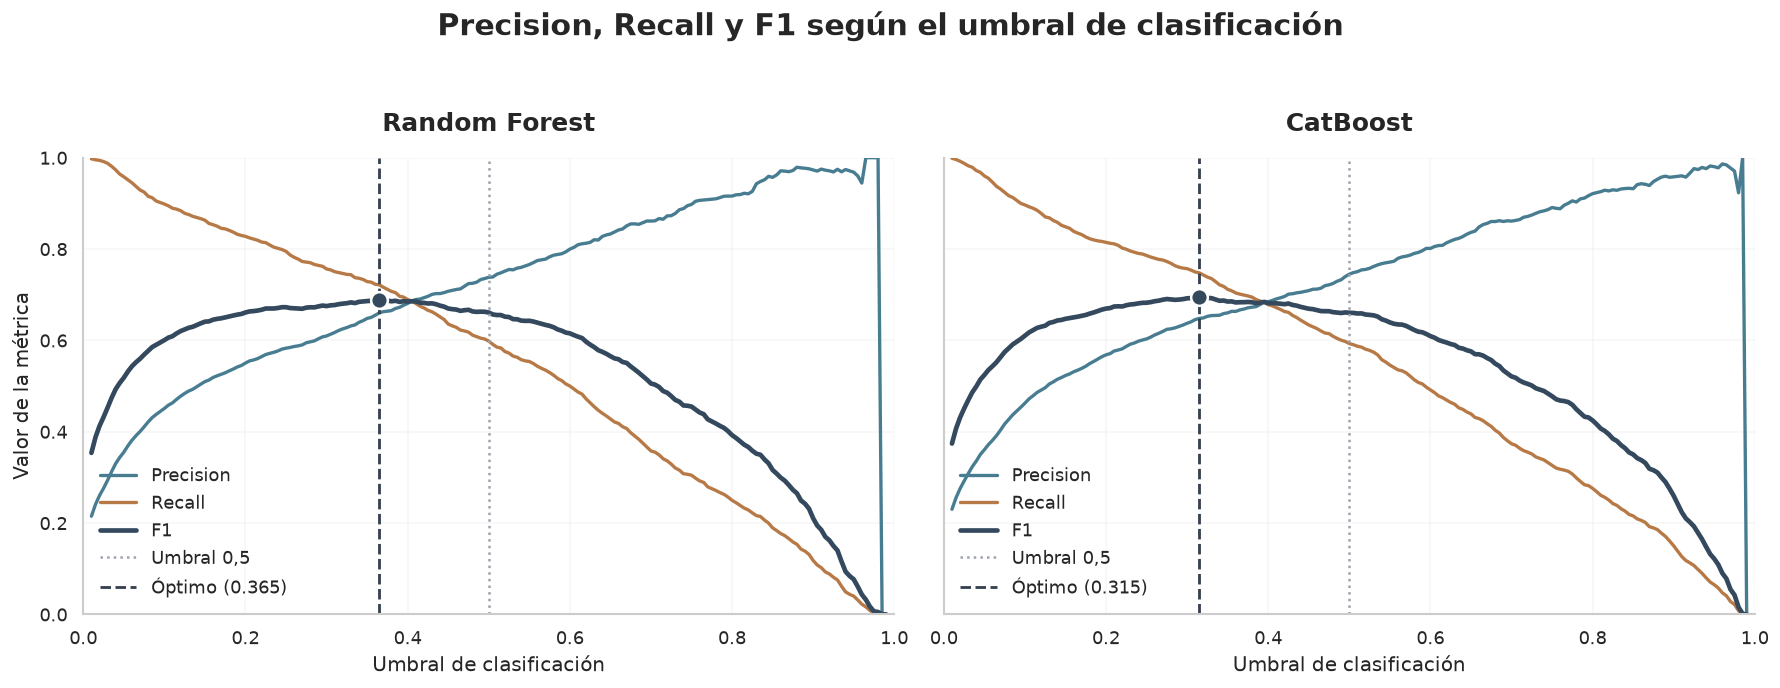

In [7]:
# Evolución de las métricas según el umbral

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5.5), sharey=True
)

colores = {
    "Precision": "#487D91",
    "Recall": "#B77946",
    "F1": "#34495E"
}

for ax, nombre in zip(
    axes, ["Random Forest", "CatBoost"]
):

    curvas = curvas_umbrales[nombre]
    umbral_optimo = curvas["Umbral óptimo"]

    for metrica in ["Precision", "Recall", "F1"]:

        ax.plot(
            umbrales,
            curvas[metrica],
            color=colores[metrica],
            linewidth=2.8 if metrica == "F1" else 2,
            label=metrica
        )

    # Umbral predeterminado
    ax.axvline(
        0.5,
        color="#9CA3AF",
        linestyle=":",
        linewidth=1.5,
        label="Umbral 0,5"
    )

    # Mejor umbral encontrado
    ax.axvline(
        umbral_optimo,
        color="#374151",
        linestyle="--",
        linewidth=1.7,
        label=f"Óptimo ({umbral_optimo:.3f})"
    )

    f1_optimo = tabla_umbrales.loc[nombre, "F1 óptimo"]

    ax.scatter(
        umbral_optimo,
        f1_optimo,
        color="#34495E",
        s=100,
        edgecolor="white",
        linewidth=1.5,
        zorder=5
    )

    ax.set_title(nombre, fontsize=15, pad=16)
    ax.set_xlabel("Umbral de clasificación")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.15)

    ax.legend(frameon=False, loc="lower left")

axes[0].set_ylabel("Valor de la métrica")

fig.suptitle(
    "Precision, Recall y F1 según el umbral de clasificación",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** el mejor umbral es 0,365, aumentando
  el F1 de 0,6609 a 0,6894.


- **CatBoost:** el mejor umbral es 0,315, elevando el F1
  de 0,6603 a 0,6943.


- Ambos umbrales son inferiores a 0,5, lo que permite
  identificar más compradores a costa de aceptar más
  falsos positivos.

  
- CatBoost presenta una ligera ventaja, con un Recall
  de 0,7477 frente al 0,7215 de Random Forest.

**Decisión:** fijamos los umbrales seleccionados mediante
predicciones OOF y los utilizaremos en la evaluación final.

La selección del umbral puede introducir cierto optimismo
en el F1 obtenido sobre entrenamiento. Su generalización
se comprobará en el conjunto de prueba independiente.

## 3. Evaluación final sobre el conjunto de prueba

Una vez seleccionados los hiperparámetros y los umbrales
de clasificación, evaluamos los modelos sobre las 2.441
sesiones reservadas.

Entrenamos cada algoritmo con el conjunto completo de
entrenamiento, manteniendo las configuraciones seleccionadas:

- **Random Forest:** 17 características y umbral 0,365.


- **CatBoost:** 22 características y umbral 0,315.

Calcularemos Average Precision y ROC AUC a partir de las
probabilidades, y Precision, Recall y F1 utilizando los
umbrales previamente seleccionados.

No modificaremos las configuraciones en función de los
resultados del conjunto de prueba.

In [8]:
# Random Forest
preprocesador_final = ColumnTransformer([
    ("num", "passthrough", numericas_rf),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), variables_categoricas)
])

modelo_rf_final = Pipeline([
    ("preprocesamiento", preprocesador_final),
    ("clasificador", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=8,
        max_features=0.5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

modelo_rf_final.fit(X_train, y_train)


# CatBoost
modelo_cb_final = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.02,
    l2_leaf_reg=1,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

modelo_cb_final.fit(
    X_train_cb,
    y_train,
    cat_features=variables_categoricas
)

# Preparar el test para CatBoost
X_test_cb = crear_caracteristicas(X_test)

for columna in variables_categoricas:
    X_test_cb[columna] = X_test_cb[columna].astype(str)

X_test_cb = X_test_cb[X_train_cb.columns]

# Probabilidades sobre test
probabilidades_test = {
    "Random Forest": modelo_rf_final.predict_proba(X_test)[:, 1],
    "CatBoost": modelo_cb_final.predict_proba(X_test_cb)[:, 1]
}

# Umbrales fijados previamente con entrenamiento OOF
umbrales_finales = tabla_umbrales["Umbral óptimo"].to_dict()

print("Modelos entrenados y predicciones de test calculadas.")
print(f"Sesiones evaluadas: {len(y_test):,}")

Modelos entrenados y predicciones de test calculadas.
Sesiones evaluadas: 2,441


### 3.2. Comparación de métricas en test

Comparamos la capacidad predictiva de Random Forest y
CatBoost mediante las siguientes métricas:

- **Average Precision y ROC AUC:** discriminación de
  compradores utilizando las probabilidades estimadas.


- **Precision:** proporción de compras reales entre las
  sesiones clasificadas como compradoras.


- **Recall:** proporción de compradores identificados.


- **F1:** equilibrio entre Precision y Recall.

Para las métricas de clasificación utilizamos los umbrales
seleccionados previamente sobre entrenamiento.

In [9]:
resultados_test = []

for nombre, probabilidades in probabilidades_test.items():

    umbral = umbrales_finales[nombre]
    predicciones = (probabilidades >= umbral).astype(int)

    resultados_test.append({
        "Modelo": nombre,
        "Umbral": umbral,
        "AP": average_precision_score(y_test, probabilidades),
        "ROC AUC": roc_auc_score(y_test, probabilidades),
        "Precision": precision_score(y_test, predicciones),
        "Recall": recall_score(y_test, predicciones),
        "F1": f1_score(y_test, predicciones)
    })

tabla_test = (
    pd.DataFrame(resultados_test)
    .set_index("Modelo")
    .sort_values("AP", ascending=False)
)

display(
    tabla_test.style
    .format("{:.4f}")
    .background_gradient(
        subset=["AP", "F1"],
        cmap="Blues"
    )
)

,Umbral,AP,ROC AUC,Precision,Recall,F1
Modelo,,,,,,
Random Forest,0.3650,0.7564,0.9356,0.6626,0.7147,0.6877
CatBoost,0.3150,0.7521,0.9352,0.6225,0.7382,0.6754


In [10]:
# Comparación entre umbral 0,5 y umbral optimizado

resultados_comparacion = []

for nombre, probabilidades in probabilidades_test.items():

    for tipo, umbral in [
        ("Predeterminado (0,5)", 0.5),
        ("Optimizado (OOF)", umbrales_finales[nombre])
    ]:

        predicciones = (probabilidades >= umbral).astype(int)

        resultados_comparacion.append({
            "Modelo": nombre,
            "Tipo de umbral": tipo,
            "Umbral": umbral,
            "Precision": precision_score(
                y_test, predicciones, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predicciones, zero_division=0
            ),
            "F1": f1_score(
                y_test, predicciones, zero_division=0
            ),
            "Compras predichas": predicciones.sum()
        })

tabla_comparacion_umbrales = pd.DataFrame(
    resultados_comparacion
).set_index(["Modelo", "Tipo de umbral"])

display(
    tabla_comparacion_umbrales.style
    .format({
        "Umbral": "{:.3f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "Compras predichas": "{:,.0f}"
    })
    .background_gradient(
        subset=["F1"],
        cmap="Blues"
    )
)

**Interpretación**

- **Random Forest:** reducir el umbral de 0,5 a 0,365 mejora el F1 de 0,6648 a **0,6877**, aumentando el Recall del 61,5 % al 71,5 % a costa de reducir la Precision.


- **CatBoost:** el umbral de 0,315 aumenta el Recall del 62,8 % al 73,8 %, pero la pérdida de Precision hace que el F1 apenas mejore (0,6723 → 0,6754).


- El ajuste del umbral resulta especialmente beneficioso para Random Forest. En CatBoost, su utilidad dependerá de si se prioriza identificar más compradores o evitar falsos positivos.

**Decisión:** mantenemos los umbrales seleccionados mediante validación cruzada para la comparación principal y conservamos el umbral de 0,5 como referencia.

### 3.3. Curvas Precision-Recall y ROC

Evaluamos la capacidad de discriminación de ambos modelos
utilizando las probabilidades estimadas sobre el conjunto
de prueba.

- **Curva Precision-Recall:** representa el compromiso entre
  precisión y sensibilidad para distintos umbrales. Es
  especialmente relevante ante el desequilibrio de clases.

  
- **Curva ROC:** representa la tasa de verdaderos positivos
  frente a la tasa de falsos positivos.

Utilizamos Average Precision (AP) y el área bajo la curva
ROC (ROC AUC) para resumir el rendimiento.

Ambas curvas permiten comparar los algoritmos sin depender
de un único umbral de clasificación.

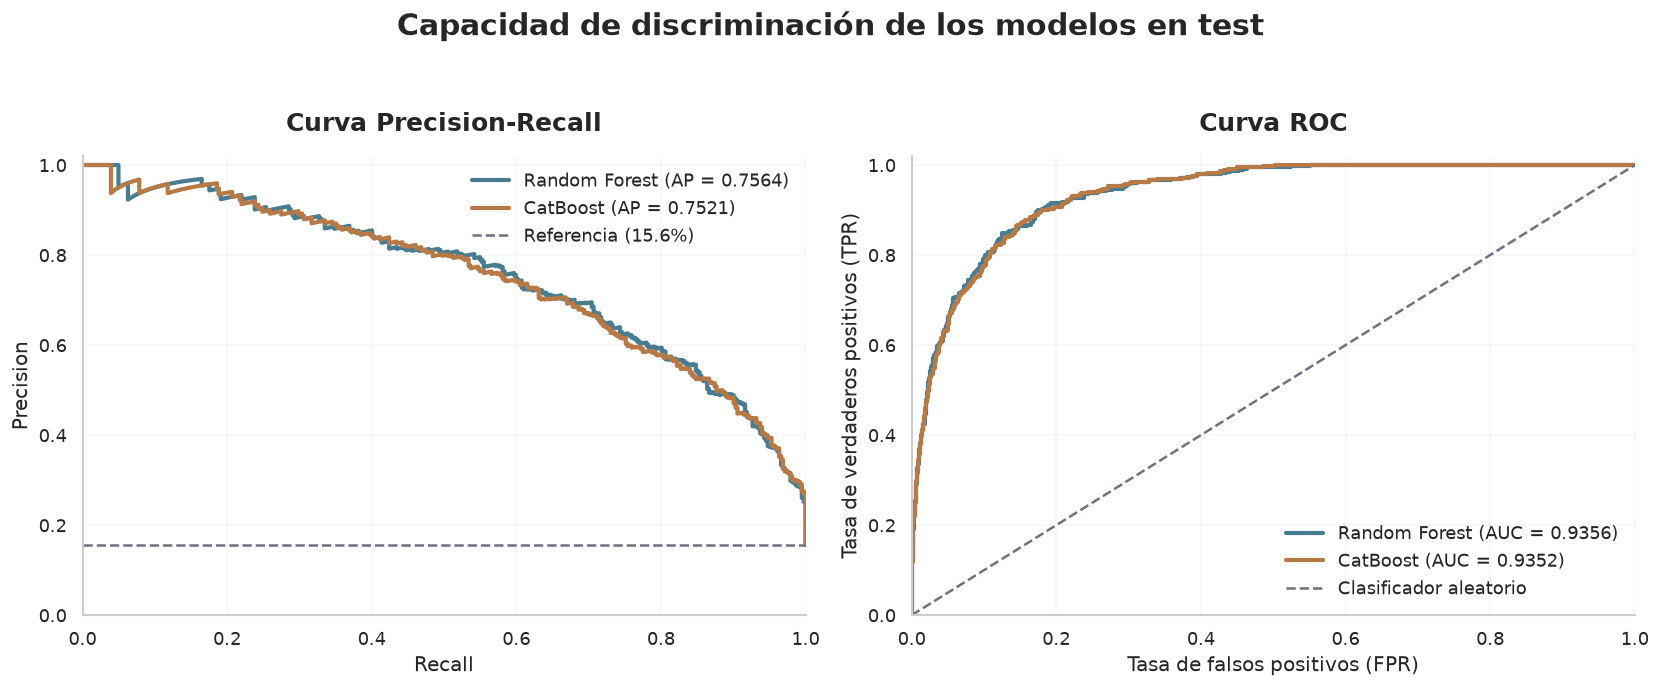

In [11]:
colores_modelos = {
    "Random Forest": "#487D91",
    "CatBoost": "#B77946"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for nombre, probabilidades in probabilidades_test.items():

    color = colores_modelos[nombre]

    # Curva Precision-Recall
    precision, recall, _ = precision_recall_curve(
        y_test, probabilidades
    )

    ap = average_precision_score(y_test, probabilidades)

    axes[0].plot(
        recall,
        precision,
        color=color,
        linewidth=2.5,
        label=f"{nombre} (AP = {ap:.4f})"
    )

    # Curva ROC
    fpr, tpr, _ = roc_curve(
        y_test, probabilidades
    )

    auc = roc_auc_score(y_test, probabilidades)

    axes[1].plot(
        fpr,
        tpr,
        color=color,
        linewidth=2.5,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

# Referencia: prevalencia de compradores
prevalencia = y_test.mean()

axes[0].axhline(
    prevalencia,
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label=f"Referencia ({prevalencia:.1%})"
)

# Referencia: clasificador aleatorio
axes[1].plot(
    [0, 1], [0, 1],
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label="Clasificador aleatorio"
)

axes[0].set_title("Curva Precision-Recall", fontsize=15, pad=15)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")

axes[1].set_title("Curva ROC", fontsize=15, pad=15)
axes[1].set_xlabel("Tasa de falsos positivos (FPR)")
axes[1].set_ylabel("Tasa de verdaderos positivos (TPR)")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, loc="best")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Capacidad de discriminación de los modelos en test",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Precision-Recall:** ambos modelos se mantienen claramente
  por encima de la referencia aleatoria (15,6 % de compras).
  Random Forest presenta una ligera ventaja en AP
  (0,7564 frente a 0,7521).


- **ROC:** las curvas prácticamente se superponen, con valores
  de ROC AUC muy similares (0,9356 y 0,9352).

  
- Los dos algoritmos presentan una buena capacidad para
  distinguir sesiones compradoras y no compradoras.

**Conclusión:** Random Forest obtiene resultados ligeramente
superiores en test, pero las diferencias son pequeñas y no
permiten establecer una superioridad clara entre ambos modelos.

### 3.4. Matrices de confusión

Representamos las matrices de confusión de ambos modelos
utilizando los umbrales seleccionados mediante predicciones OOF:

- Random Forest: 0,365.
- CatBoost: 0,315.

Cada matriz muestra cuatro resultados:

- **Verdaderos negativos (VN):** sesiones sin compra
  correctamente identificadas.


- **Falsos positivos (FP):** sesiones sin compra clasificadas
  como compradoras.


- **Falsos negativos (FN):** compradores que el modelo no identifica.


- **Verdaderos positivos (VP):** compradores correctamente
  identificados.

Mostramos los recuentos y los porcentajes respecto al total
de cada clase real, facilitando la comparación entre modelos.

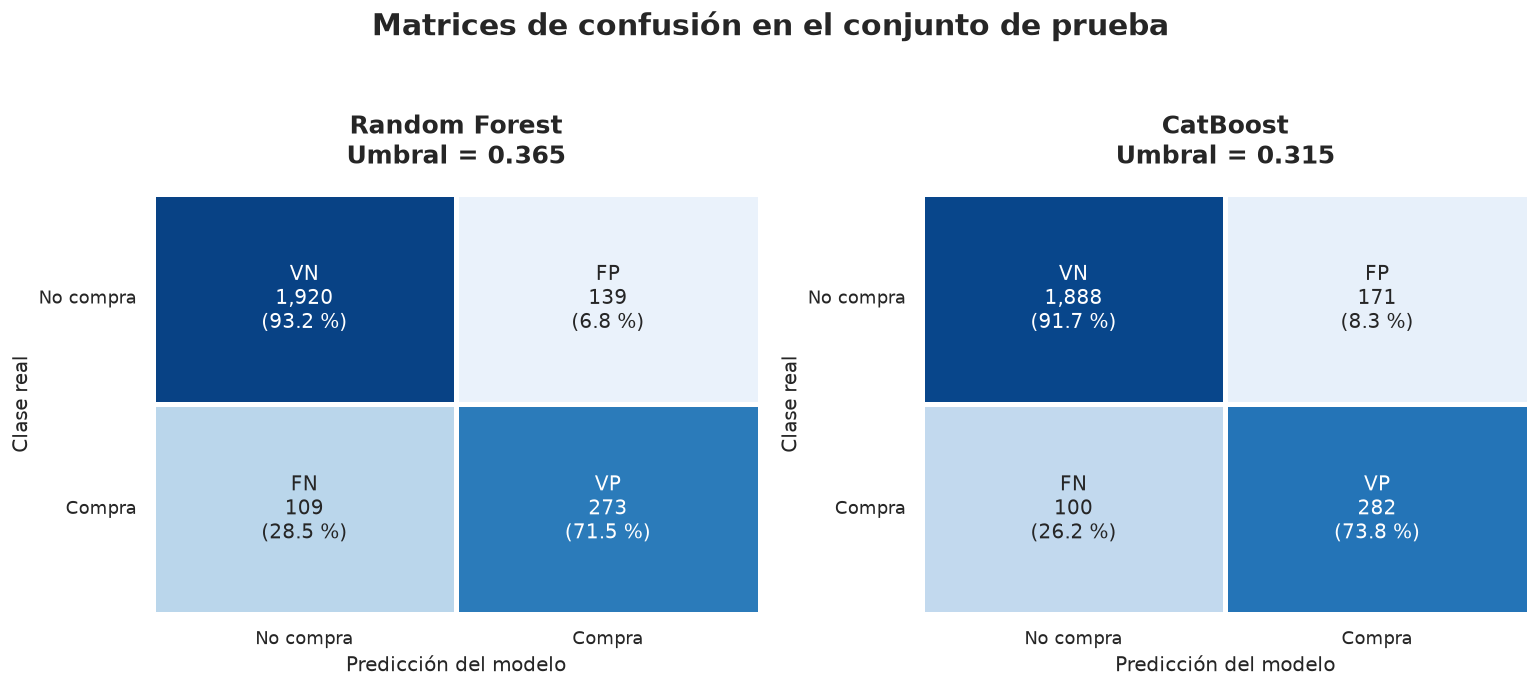

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

modelos = ["Random Forest", "CatBoost"]
etiquetas = ["No compra", "Compra"]

for ax, nombre in zip(axes, modelos):

    umbral = umbrales_finales[nombre]

    predicciones = (
        probabilidades_test[nombre] >= umbral
    ).astype(int)

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1]
    )

    # Porcentajes respecto a cada clase real
    porcentajes = (
        matriz / matriz.sum(axis=1, keepdims=True) * 100
    )

    # Recuentos y porcentajes dentro de cada celda
    nombres = [["VN", "FP"], ["FN", "VP"]]

    anotaciones = np.array([
        [
            f"{nombres[i][j]}\n"
            f"{matriz[i, j]:,}\n"
            f"({porcentajes[i, j]:.1f} %)"
            for j in range(2)
        ]
        for i in range(2)
    ])

    sns.heatmap(
        porcentajes,
        annot=anotaciones,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=100,
        cbar=False,
        linewidths=2,
        linecolor="white",
        xticklabels=etiquetas,
        yticklabels=etiquetas,
        annot_kws={"fontsize": 12},
        ax=ax
    )

    ax.set_title(
        f"{nombre}\nUmbral = {umbral:.3f}",
        fontsize=15,
        pad=18
    )

    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Matrices de confusión en el conjunto de prueba",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest:** identifica correctamente 273 de los 382 compradores (71,5 %) y genera 139 falsos positivos.
- **CatBoost:** identifica 282 compradores (73,8 %), nueve más que Random Forest, pero aumenta los falsos positivos hasta 171.
- **Compromiso comercial:** CatBoost prioriza una mayor cobertura de compradores, mientras que Random Forest ofrece predicciones positivas más precisas y obtiene un F1 superior (0,6877 frente a 0,6754).

**Conclusión:** ambos modelos presentan resultados competitivos. La elección depende del coste de los falsos positivos y del beneficio de identificar compradores adicionales, información de la que no disponemos para establecer una preferencia económica definitiva.

### 3.5. Capacidad de priorización de sesiones

Además de clasificar las sesiones, los modelos pueden utilizarse para ordenarlas según su probabilidad estimada de compra.

Evaluaremos la capacidad de priorización seleccionando el 10 %, 20 % y 30 % de las sesiones con mayor puntuación.

Para cada grupo calcularemos:

- **Precision@k:** proporción de compradores reales entre las sesiones seleccionadas.


- **Recall@k:** proporción de todos los compradores que quedan incluidos en el grupo.


- **Lift@k:** cuántas veces supera la tasa de compra del grupo a la tasa global.

Los porcentajes de selección se fijan previamente como escenarios ilustrativos, sin optimizarlos sobre los resultados de prueba.

In [13]:
resultados_priorizacion = []

y_real = y_test.to_numpy()
prevalencia = y_real.mean()

for nombre, probabilidades in probabilidades_test.items():

    # Ordenar las sesiones de mayor a menor probabilidad
    orden = np.argsort(-probabilidades, kind="stable")
    compras_ordenadas = y_real[orden]

    for porcentaje in [0.10, 0.20, 0.30]:

        k = int(np.ceil(len(y_real) * porcentaje))
        compradores = compras_ordenadas[:k].sum()

        precision_k = compradores / k
        recall_k = compradores / y_real.sum()
        lift_k = precision_k / prevalencia

        resultados_priorizacion.append({
            "Modelo": nombre,
            "Top sesiones": f"{porcentaje:.0%}",
            "Sesiones": k,
            "Compradores": compradores,
            "Precision@k": precision_k,
            "Recall@k": recall_k,
            "Lift@k": lift_k
        })

tabla_priorizacion = pd.DataFrame(resultados_priorizacion)

display(
    tabla_priorizacion.style
    .format({
        "Sesiones": "{:,.0f}",
        "Compradores": "{:,.0f}",
        "Precision@k": "{:.1%}",
        "Recall@k": "{:.1%}",
        "Lift@k": "{:.2f}x"
    })
    .background_gradient(
        subset=["Precision@k"],
        cmap="Blues"
    )
)

,Modelo,Top sesiones,Sesiones,Compradores,Precision@k,Recall@k,Lift@k
0,Random Forest,10%,245,198,80.8%,51.8%,5.16x
1,Random Forest,20%,489,295,60.3%,77.2%,3.85x
2,Random Forest,30%,733,346,47.2%,90.6%,3.02x
3,CatBoost,10%,245,195,79.6%,51.0%,5.09x
4,CatBoost,20%,489,291,59.5%,76.2%,3.80x
5,CatBoost,30%,733,345,47.1%,90.3%,3.01x


**Interpretación**

- **Top 10 %:** Random Forest identifica 198 de los 382 compradores (51,8 %) seleccionando únicamente 245 sesiones. Su tasa de compra es del 80,8 %, unas 5,16 veces la media.


- **Top 20 %:** permite identificar el 77,2 % de los compradores, con una Precision del 60,3 %.


- **Top 30 %:** concentra el 90,6 % de todas las compras del conjunto de prueba.


- **Comparación:** CatBoost presenta resultados prácticamente idénticos, aunque Random Forest mantiene una ligera ventaja.

**Conclusión:** ambos modelos permiten concentrar una proporción elevada de compradores en un grupo reducido de sesiones, demostrando su potencial para la priorización comercial.

### 3.6. Curva de ganancias acumuladas

Representamos el porcentaje acumulado de compradores identificados al seleccionar progresivamente las sesiones con mayor probabilidad estimada.

Comparamos tres referencias:

- **Modelos predictivos:** sesiones ordenadas por probabilidad de compra.


- **Selección aleatoria:** referencia sin capacidad de priorización.


- **Clasificación ideal:** todos los compradores aparecen en las primeras posiciones.

Esta visualización permite evaluar qué proporción de sesiones sería necesario priorizar para alcanzar una determinada cobertura de compradores.

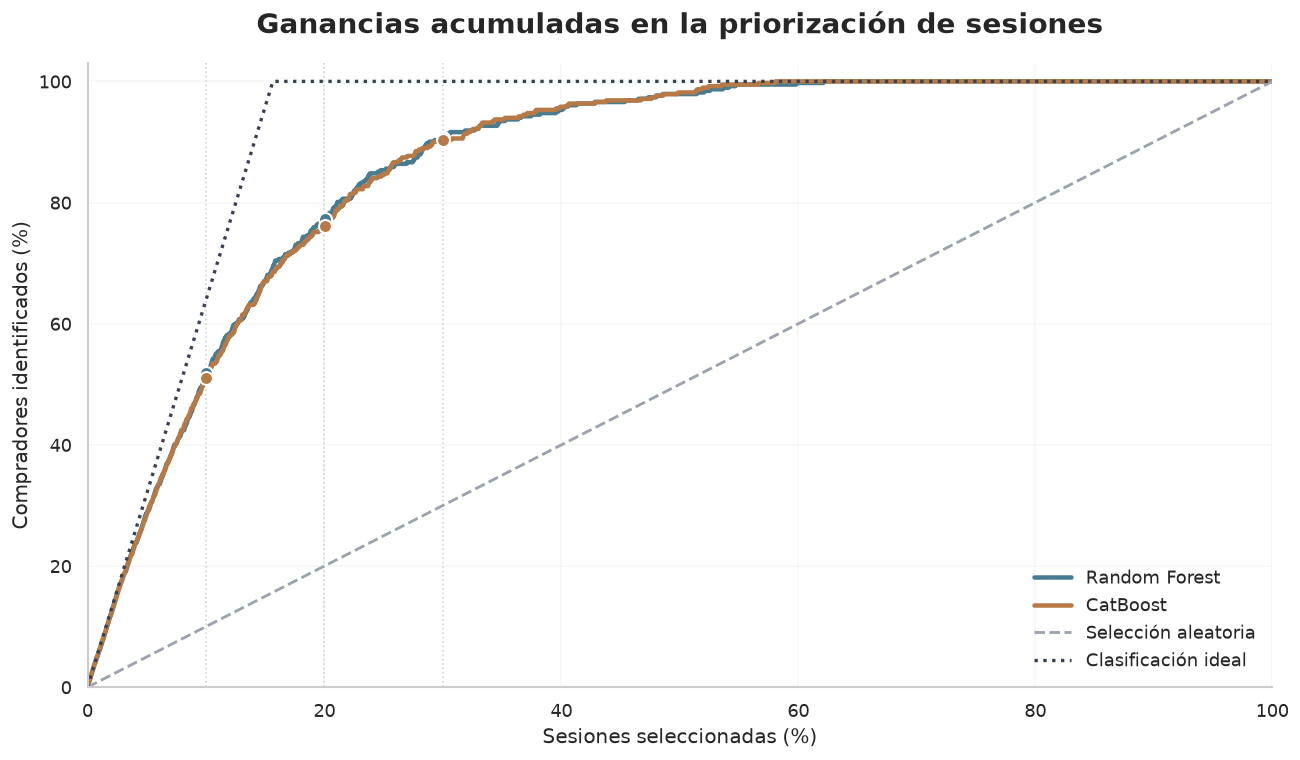

In [14]:
y_real = y_test.to_numpy()
n = len(y_real)
total_compradores = y_real.sum()

x = np.arange(n + 1) / n * 100

fig, ax = plt.subplots(figsize=(11, 6.5))

colores = {
    "Random Forest": "#487D91",
    "CatBoost": "#B77946"
}

for nombre, probabilidades in probabilidades_test.items():

    # Ordenar sesiones por probabilidad descendente
    orden = np.argsort(
        -np.asarray(probabilidades),
        kind="stable"
    )

    compras_ordenadas = y_real[orden]

    ganancia = np.r_[
        0,
        np.cumsum(compras_ordenadas)
    ] / total_compradores * 100

    ax.plot(
        x,
        ganancia,
        color=colores[nombre],
        linewidth=2.7,
        label=nombre
    )

    # Destacar el 10 %, 20 % y 30 % de las sesiones
    for porcentaje in [0.10, 0.20, 0.30]:
        k = int(np.ceil(n * porcentaje))

        ax.scatter(
            x[k],
            ganancia[k],
            color=colores[nombre],
            s=60,
            edgecolor="white",
            linewidth=1.2,
            zorder=4
        )

# Referencia aleatoria
ax.plot(
    [0, 100], [0, 100],
    color="#9CA3AF",
    linestyle="--",
    linewidth=1.7,
    label="Selección aleatoria"
)

# Clasificación ideal
ganancia_ideal = np.minimum(
    np.arange(n + 1) / total_compradores * 100,
    100
)

ax.plot(
    x,
    ganancia_ideal,
    color="#374151",
    linestyle=":",
    linewidth=2,
    label="Clasificación ideal"
)

# Marcar las proporciones estudiadas
for porcentaje in [10, 20, 30]:
    ax.axvline(
        porcentaje,
        color="#D1D5DB",
        linestyle=":",
        linewidth=1,
        zorder=0
    )

ax.set_xlim(0, 100)
ax.set_ylim(0, 103)

ax.set_xlabel("Sesiones seleccionadas (%)")
ax.set_ylabel("Compradores identificados (%)")

ax.set_title(
    "Ganancias acumuladas en la priorización de sesiones",
    fontsize=17,
    pad=18
)

ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

**Interpretación**

- **Top 10 %:** Random Forest identifica el 51,8 % de todos los compradores seleccionando únicamente el 10 % de las sesiones.
- **Top 20 %:** ambos modelos identifican aproximadamente el 77 % de los compradores, frente al 20 % esperado mediante selección aleatoria.
- **Top 30 %:** se alcanza una cobertura superior al 90 % de las compras.
- **Comparación:** las curvas de Random Forest y CatBoost prácticamente se superponen, confirmando su rendimiento similar en priorización.

**Conclusión:** ambos modelos permiten concentrar las sesiones con mayor probabilidad de compra, ofreciendo una herramienta potencialmente útil para orientar acciones comerciales con recursos limitados.

## 4. Conclusiones y selección del modelo definitivo

La evaluación sobre las **2.441 sesiones del conjunto de prueba** confirma que Random Forest y CatBoost presentan una elevada capacidad para distinguir compradores y no compradores, con diferencias pequeñas entre ambos.

### 4.1. Resultados principales

| Métrica | Random Forest | CatBoost |
|---|---:|---:|
| Average Precision | **0,7564** | 0,7521 |
| ROC AUC | **0,9356** | 0,9352 |
| Precision | **0,6626** | 0,6225 |
| Recall | 0,7147 | **0,7382** |
| F1 | **0,6877** | 0,6754 |

**Principales hallazgos:**

- **Ajuste del umbral:** los umbrales seleccionados mediante validación cruzada mejoran el F1 frente al valor predeterminado de 0,5, especialmente en Random Forest (0,6648 → 0,6877).
- **Errores de clasificación:** CatBoost identifica nueve compradores adicionales, pero genera 32 falsos positivos más que Random Forest.
- **Priorización comercial:** Random Forest identifica el **51,8 % de los compradores seleccionando únicamente el 10 % de las sesiones** con mayor puntuación. Al ampliar la selección al 20 %, la cobertura alcanza el 77,2 %, muy por encima de una selección aleatoria.

### 4.2. Selección del modelo definitivo

Seleccionamos **Random Forest** como modelo final del proyecto, por tres motivos:

1. **Rendimiento:** obtiene resultados ligeramente superiores en Average Precision, F1 y Precision sobre el conjunto de prueba.
2. **Simplicidad:** utiliza las 17 características originales, sin necesidad de incorporar las cinco variables derivadas utilizadas por CatBoost.
3. **Integración:** La configuración seleccionada facilita la integración en Streamlit, ya que utiliza las características originales y permite reutilizar directamente el pipeline entrenado.

La configuración seleccionada es:

| Elemento | Configuración |
|---|---|
| Algoritmo | Random Forest |
| Número de árboles | 300 |
| Profundidad máxima | 8 |
| Muestras mínimas por hoja | 8 |
| `max_features` | 0,5 |
| Balanceo de clases | Ninguno |
| Características | 17 originales |
| Umbral de clasificación | **0,365** |

Aunque Random Forest obtiene una ligera ventaja, las diferencias no permiten afirmar una superioridad estadística general sobre CatBoost. La elección combina los resultados observados con la simplicidad de implementación.

### 4.3. Limitaciones y aplicación práctica

- **Dependencia de PageValues:** el rendimiento depende considerablemente de esta característica. Su uso en predicciones durante una visita real requiere justificar que la información está disponible antes de que se produzca la compra.
- **Priorización frente a intervención:** identificar usuarios con mayor probabilidad de comprar no implica necesariamente identificar aquellos cuya decisión pueda modificarse mediante una acción comercial.
- **Evaluación independiente:** el conjunto de prueba se mantuvo reservado durante la optimización. No obstante, sus resultados también se han considerado al elegir el modelo definitivo, por lo que esta elección deberá declararse de forma transparente y no utilizarse para realizar nuevos ajustes.

**Conclusión general:** Random Forest ofrece un equilibrio adecuado entre capacidad predictiva, identificación de compradores y simplicidad. Se utilizará como modelo definitivo en Streamlit, incorporando la predicción de compra, la priorización de sesiones y las explicaciones individuales de sus resultados.

## 5. Guardado del modelo final

In [15]:
import joblib

ruta_modelo = RAIZ / "models" / "random_forest_final.joblib"
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)

artefacto = {
    "modelo": modelo_rf_final,
    "umbral": float(umbrales_finales["Random Forest"])
}

joblib.dump(artefacto, ruta_modelo)

# Comprobar que se ha guardado correctamente
cargado = joblib.load(ruta_modelo)

assert np.allclose(
    modelo_rf_final.predict_proba(X_test.head(5)),
    cargado["modelo"].predict_proba(X_test.head(5))
)

print("Modelo guardado correctamente.")
print(f"Ruta: {ruta_modelo}")
print(f"Variables: {len(modelo_rf_final.feature_names_in_)}")
print(f"Umbral: {cargado['umbral']:.3f}")

Modelo guardado correctamente.
Ruta: /home/iav/universidad/IAOrg/PROYECTO/online-shopping-prediction/models/random_forest_final.joblib
Variables: 17
Umbral: 0.365
